# Predictive Memory Leak Detection — 03: Multivariate LSTM

This notebook trains one small LSTM per recording and compares it with your verified statistical baselines. It uses real measured results; it does not assume that LSTM will win.

## What to do
1. Upload **this notebook** to Colab. CPU works; an available GPU is also supported. No paid runtime is required by the code.
2. Run the cells in order. When prompted, upload **`review2_lstm_inputs.zip`**, approximately 29 MB. This new package already contains your prepared data and baseline results, so there is only one upload.
3. The notebook trains four models and prints progress after each epoch. Let the training cell finish before running the result cells.
4. Review the measured scores, charts and final integrity message.
5. Save the downloaded **`review2_lstm_results.zip`** as `review2_lstm_results_colab.zip` in your project's `data/packages` folder. Also retain a copy of the executed notebook.

## Architecture and fixed pilot choices
**60 past observations × available system features → one 32-unit LSTM → one linear output → future memory pressure.** The hidden state resets for every input window. The inputs contain no fault labels or future data.

- Seven input features for Antarex and Westermo 2; eight for Westermo 1/3. Each recording has its own model.
- The exact existing time splits and prediction horizons remain: 60 seconds for Antarex; five minutes for Westermo.
- Seed 42, Adam learning rate 0.001, batches of 64, gradient clipping at norm 1, maximum 20 epochs.
- Training uses every 12th Antarex window and every 4th Westermo window to limit CPU cost. Full validation and test windows are retained.
- Select the lowest validation-RMSE checkpoint; stop after four epochs without a new minimum. All models finish selection before test scoring.
- Targets use the existing training-only memory-pressure scaler. Score forecasts after reversing scaling and applying the same [0,1] clipping rule as the baselines.
- No test-driven parameter search, residual shortcut, dropout or additional hidden layers are used in this initial run.

The small model, spacing and one-seed run are a declared pilot scope, not a tuned optimum or a full robustness study. GPU and CPU results need not be bit-identical even with fixed seeds; each run saves its versions, weights and predictions.

## References
Review 1 reference [3], [Assi et al. (2022)](https://doi.org/10.22075/ijnaa.2022.26974.3505), motivates the statistical/LSTM comparison. Implementation follows the primary [PyTorch LSTM documentation](https://docs.pytorch.org/docs/2.8/generated/torch.nn.LSTM.html) and [reproducibility guidance](https://docs.pytorch.org/docs/2.8/notes/randomness.html). All experiment numbers below come from this notebook's execution.


## 1. Prepare the runtime
The notebook uses Colab's available PyTorch installation, including GPU support when present. If PyTorch is missing, a CPU version is installed. Existing plotting/numerical packages are retained and their loaded versions are recorded.

In [1]:
import importlib.util
from pathlib import Path
import subprocess
import sys

if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','torch==2.8.0',
                           '--index-url','https://download.pytorch.org/whl/cpu'])
missing=[name for name in ['numpy','pandas','matplotlib','PIL'] if importlib.util.find_spec(name) is None]
if missing:
    packages=[('pillow' if name=='PIL' else name) for name in missing]
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*packages])
print('Dependencies are ready.')


Dependencies are ready.


## 2. Upload the LSTM input package and choose checkpoint storage
Leave the optional Drive setting off for a straightforward run. Checkpoints are saved after every epoch; rerunning in the same runtime resumes them. **To retain checkpoints across Colab runtime resets**, enable the Drive option before training and authorize your own Drive connection. Otherwise, download the final results before the runtime ends. Changing devices/framework versions midway through a resumed run requires a separate output folder or the original configuration.

In [2]:
USE_GOOGLE_DRIVE = False #@param {type:"boolean"}

try:
    IN_COLAB=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB=False
if IN_COLAB:
    WORK=Path('/content/memory_leak_lstm')
    INPUT_PACKAGE=Path('/content/review2_lstm_inputs.zip')
    if not INPUT_PACKAGE.exists():
        from google.colab import files
        uploaded=files.upload()
        if 'review2_lstm_inputs.zip' not in uploaded:
            raise FileNotFoundError('Select review2_lstm_inputs.zip and rerun this cell.')
        INPUT_PACKAGE.write_bytes(uploaded['review2_lstm_inputs.zip'])
        del uploaded
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        SAVED=Path('/content/drive/MyDrive/MemoryLeak_Review2_LSTM')
    else:
        SAVED=WORK
else:
    WORK=Path.cwd().resolve()
    if not (WORK/'data/packages/review2_lstm_inputs.zip').exists() and (WORK.parent/'data/packages/review2_lstm_inputs.zip').exists():
        WORK=WORK.parent
    INPUT_PACKAGE=WORK/'data/packages/review2_lstm_inputs.zip'
    SAVED=WORK
SOURCE=WORK/'data/lstm_inputs'
OUTPUT=SAVED/'results/lstm'
RESULT_PACKAGE=SAVED/'data/packages/review2_lstm_results.zip'
print('Input:',INPUT_PACKAGE)
print('Checkpoint/output folder:',OUTPUT)


Input: C:\dhruv\VIT\Sem-5\OS\Research_Project\data\packages\review2_lstm_inputs.zip
Checkpoint/output folder: C:\dhruv\VIT\Sem-5\OS\Research_Project\results\lstm


## 3. Load the complete LSTM implementation
No other source files need uploading. The code includes input-manifest verification, causal windows, checkpoint saving, validation-based selection, forecast comparisons and scientific figures. The project tests check future-data isolation, hidden-state isolation, optimization, weight reloads and interrupted-run resumption.

In [3]:
"""A fixed, small multivariate LSTM experiment for the Review 2 pilot."""
from __future__ import annotations
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

from datetime import datetime, timezone
import hashlib
import io
import json
from pathlib import Path
import platform
import random
import time
import zipfile

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

PROTOCOL_VERSION='review2-lstm-v1'
PREP_SHA256='287ffaa139819f78f493e540e527c56ac0c240477034c76fa8b258b94d5e6bb2'
BASELINE_SHA256='2b242a47288ea5db25ddd4d79de2069980ef1dc462fea157580e67ec19c01ba3'
SETTINGS={'hidden_units':32,'layers':1,'batch_size':64,'evaluation_batch_size':256,
          'learning_rate':.001,'max_epochs':20,'patience':4,'gradient_clip_norm':1.,
          'seed':42,'antarex_training_stride':12,'westermo_training_stride':4,
          'cpu_threads':2,'forecast_clip_range':[0.,1.]}
FORBIDDEN_FEATURES={'leak_active','fault_type','episode_id','timestamp','label_known','split_code'}


def dump_json(path, value):
    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')


def file_sha256(path):
    result=hashlib.sha256()
    with Path(path).open('rb') as src:
        while block:=src.read(4*1024*1024): result.update(block)
    return result.hexdigest()


def extract_manifest_archive(content, destination):
    destination=Path(destination).resolve()
    destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        manifest=json.loads(archive.read('MANIFEST.json'))
        names=archive.namelist()
        listed=[f['entry'] for f in manifest['files']]
        if len(names)!=len(set(names)) or len(listed)!=len(set(listed)) or set(names)!=set(listed)|{'MANIFEST.json'}:
            raise ValueError('Unexpected/duplicate archive entries')
        for item in manifest['files']:
            path=(destination/item['entry']).resolve()
            if not path.is_relative_to(destination): raise ValueError('Unsafe archive entry')
            data=archive.read(item['entry'])
            if len(data)!=item['bytes'] or hashlib.sha256(data).hexdigest()!=item['sha256']:
                raise ValueError('Input verification failed: '+item['entry'])
            path.parent.mkdir(parents=True,exist_ok=True)
            path.write_bytes(data)
    return manifest


def unpack_inputs(package, destination):
    destination=Path(destination)
    expected={'review2_preprocessed_colab.zip':PREP_SHA256,'review2_baseline_results_colab.zip':BASELINE_SHA256}
    with zipfile.ZipFile(package) as archive:
        if set(archive.namelist())!=set(expected)|{'MANIFEST.json'} or len(archive.namelist())!=3:
            raise ValueError('Upload review2_lstm_inputs.zip, containing the two verified input packages.')
        for name,digest in expected.items():
            content=archive.read(name)
            if hashlib.sha256(content).hexdigest()!=digest: raise ValueError('Unexpected source package: '+name)
            target=destination/('prepared' if name.startswith('review2_preprocessed') else 'baselines')
            extract_manifest_archive(content,target)
    prep=json.loads((destination/'prepared/preprocessing_summary.json').read_text())
    baseline=json.loads((destination/'baselines/experiment_summary.json').read_text())
    if baseline['input_package_sha256']!=PREP_SHA256: raise ValueError('Baseline input provenance mismatch')
    return destination,{'combined_package_sha256':file_sha256(package),
                        'prepared_package_sha256':PREP_SHA256,'baseline_package_sha256':BASELINE_SHA256,
                        'datasets':[d['dataset'] for d in prep['datasets']]}


def configure_runtime(device_choice='auto'):
    torch.set_num_threads(SETTINGS['cpu_threads'])
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    device=torch.device('cuda' if device_choice=='auto' and torch.cuda.is_available() else ('cpu' if device_choice=='auto' else device_choice))
    return device,{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                  'torch':str(torch.__version__),'matplotlib':matplotlib.__version__,'device_type':device.type,
                  'device_name':torch.cuda.get_device_name(device) if device.type=='cuda' else (platform.processor() or 'CPU'),
                  'cuda':torch.version.cuda,'cudnn':torch.backends.cudnn.version(),
                  'deterministic_algorithms':True,'cpu_threads':torch.get_num_threads()}


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


class MemoryLSTM(nn.Module):
    def __init__(self,features,hidden_units=32):
        super().__init__()
        self.lstm=nn.LSTM(features,hidden_units,num_layers=1,batch_first=True,bidirectional=False)
        self.output=nn.Linear(hidden_units,1)

    def forward(self,x):
        # No recurrent state is carried between windows or batches.
        sequence,_=self.lstm(x)
        return self.output(sequence[:,-1,:]).squeeze(-1)


def gather_history(features, origins, history_steps):
    origins=np.asarray(origins,dtype=np.int64)
    offsets=np.arange(history_steps-1,-1,-1,dtype=np.int64)
    indices=origins[:,None]-offsets
    if indices.min()<0 or indices.max()>=len(features): raise ValueError('Invalid history indices')
    return np.ascontiguousarray(features[indices],dtype=np.float32)


def load_recording(source,info):
    base=Path(source)/'prepared'/info['dataset']
    with np.load(base/'model_arrays.npz',allow_pickle=False) as archive:
        arrays={k:archive[k] for k in archive.files}
    names=arrays['feature_names'].tolist()
    scaler=json.loads((base/'scaler.json').read_text())
    if names!=info['feature_names'] or names!=scaler['features'] or set(names)&FORBIDDEN_FEATURES:
        raise ValueError('Unexpected model features')
    assert scaler['fit_partition']=='train'
    assert np.isfinite(arrays['features'][arrays['valid']]).all()
    windows=pd.read_csv(base/'forecast_windows.csv.gz')
    h,o,z=(windows[c].to_numpy(dtype=np.int64) for c in ['history_start_index','origin_index','target_index'])
    valid,split,t=arrays['valid'],arrays['split_code'],arrays['timestamps']
    invalid_prefix=np.r_[0,np.cumsum(~valid)]
    assert h.min()>=0 and z.max()<len(t)
    assert (invalid_prefix[z+1]-invalid_prefix[h]==0).all()
    assert (split[h]==split[z]).all() and (split[o]==windows['split_code']).all()
    assert (o-h+1==info['history_steps']).all()
    assert (t[z]-t[h]==(info['history_steps']-1+info['horizon_steps'])*info['cadence_seconds']).all()
    assert windows['origin_index'].is_unique
    for name,code in [('train',0),('validation',1),('test',2)]:
        assert (windows.loc[windows['split'].eq(name),'split_code']==code).all()
    arrays['target_mean']=float(scaler['mean']['memory_pressure'])
    arrays['target_std']=float(scaler['std']['memory_pressure'])
    assert arrays['target_std']>0
    return arrays,windows


def predict_raw(model, arrays, origins, history_steps, device, batch_size=256):
    model.eval()
    outputs=[]
    with torch.inference_mode():
        for start in range(0,len(origins),batch_size):
            x=gather_history(arrays['features'],origins[start:start+batch_size],history_steps)
            pred=model(torch.from_numpy(x).to(device)).cpu().numpy().astype(np.float64)
            outputs.append(pred*arrays['target_std']+arrays['target_mean'])
    result=np.concatenate(outputs)
    if not np.isfinite(result).all(): raise ValueError('Nonfinite LSTM predictions')
    return result


def regression_errors(actual,prediction):
    actual,prediction=np.asarray(actual,dtype=np.float64),np.asarray(prediction,dtype=np.float64)
    if actual.shape!=prediction.shape or not len(actual) or not np.isfinite(actual).all() or not np.isfinite(prediction).all():
        raise ValueError('Invalid paired forecasts')
    delta=prediction-actual
    mae,rmse=float(np.abs(delta).mean()),float(np.sqrt(np.square(delta).mean()))
    return {'n':len(actual),'mae_fraction':mae,'rmse_fraction':rmse,
            'mae_percentage_points':100*mae,'rmse_percentage_points':100*rmse}


def atomic_torch_save(value,path):
    path=Path(path); temporary=path.with_suffix(path.suffix+'.tmp')
    torch.save(value,temporary); temporary.replace(path)


def cpu_weights(model):
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}


def should_stop(history,patience):
    if not history: return False
    best=min(range(len(history)),key=lambda i:history[i]['validation_rmse_fraction'])
    return len(history)-1-best>=patience


def train_recording(arrays,windows,info,output,device,runtime,settings=None):
    settings=dict(SETTINGS if settings is None else settings)
    output=Path(output); output.mkdir(parents=True,exist_ok=True)
    seed_everything(settings['seed'])
    rng=np.random.default_rng(settings['seed'])
    stride=settings['antarex_training_stride'] if info['dataset'].startswith('antarex') else settings['westermo_training_stride']
    train=windows[windows['split'].eq('train')].iloc[::stride].copy()
    val=windows[windows['split'].eq('validation')]
    origins=train['origin_index'].to_numpy(dtype=np.int64)
    targets=train['target_index'].to_numpy(dtype=np.int64)
    vo,vz=(val[c].to_numpy(dtype=np.int64) for c in ['origin_index','target_index'])
    assert (arrays['split_code'][origins]==0).all() and (arrays['split_code'][targets]==0).all()
    assert (arrays['split_code'][vo]==1).all() and (arrays['split_code'][vz]==1).all()
    config={'protocol_version':PROTOCOL_VERSION,'dataset':info['dataset'],'settings':settings,
            'prepared_package_sha256':PREP_SHA256,'feature_names':info['feature_names'],
            'history_steps':info['history_steps'],'horizon_steps':info['horizon_steps'],
            'target_mean':arrays['target_mean'],'target_std':arrays['target_std'],
            'training_origin_count':len(train),'training_origin_sha256':hashlib.sha256(origins.astype('<i8').tobytes()).hexdigest(),
            'validation_origin_count':len(val),'test_used_for_selection':False,
            'runtime_device_type':device.type,'runtime_torch_version':str(torch.__version__)}
    config_hash=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
    model=MemoryLSTM(len(info['feature_names']),settings['hidden_units']).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=settings['learning_rate'])
    loss_fn=nn.MSELoss()
    history=[]; best=float('inf'); best_epoch=0; first_epoch=1; cumulative_seconds=0.
    checkpoint_path=output/'last_checkpoint.pt'
    if checkpoint_path.exists():
        checkpoint=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
        if checkpoint['config_hash']!=config_hash:
            raise ValueError('Saved training configuration differs; use its original runtime/configuration or a separate output folder.')
        model.load_state_dict(checkpoint['model'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        history=checkpoint['history']; best=checkpoint['best']; best_epoch=checkpoint['best_epoch']
        first_epoch=checkpoint['epoch']+1; cumulative_seconds=checkpoint['cumulative_seconds']
        torch.set_rng_state(checkpoint['torch_rng'])
        rng.bit_generator.state=checkpoint['numpy_generator_state']
        if device.type=='cuda' and checkpoint['cuda_rng'] is not None: torch.cuda.set_rng_state_all(checkpoint['cuda_rng'])
        print(info['dataset'],'resuming after epoch',checkpoint['epoch'],flush=True)
    dump_json(output/'configuration.json',config)
    np.save(output/'training_origins.npy',origins,allow_pickle=False)
    if not should_stop(history,settings['patience']):
        for epoch in range(first_epoch,settings['max_epochs']+1):
            started=time.perf_counter(); model.train()
            order=rng.permutation(len(origins)); loss_total=0.; seen=0
            for start in range(0,len(order),settings['batch_size']):
                which=order[start:start+settings['batch_size']]
                x=torch.from_numpy(gather_history(arrays['features'],origins[which],info['history_steps'])).to(device)
                target=(arrays['target_memory_pressure'][targets[which]].astype(np.float64)-arrays['target_mean'])/arrays['target_std']
                target=torch.from_numpy(target.astype(np.float32)).to(device)
                optimizer.zero_grad(set_to_none=True)
                loss=loss_fn(model(x),target)
                if not torch.isfinite(loss): raise ValueError('Nonfinite training loss')
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),settings['gradient_clip_norm'],error_if_nonfinite=True)
                optimizer.step()
                loss_total+=float(loss.detach().cpu())*len(which); seen+=len(which)
            raw=predict_raw(model,arrays,vo,info['history_steps'],device,settings['evaluation_batch_size'])
            scores=regression_errors(arrays['target_memory_pressure'][vz],np.clip(raw,0,1))
            if scores['rmse_fraction']<best:
                best=scores['rmse_fraction']; best_epoch=epoch
                atomic_torch_save(cpu_weights(model),output/'best_weights.pt')
            seconds=time.perf_counter()-started; cumulative_seconds+=seconds
            history.append({'epoch':epoch,'training_mse_standardized':loss_total/seen,
                            'training_rmse_percentage_points_online':float(np.sqrt(loss_total/seen)*arrays['target_std']*100),
                            'validation_rmse_fraction':scores['rmse_fraction'],
                            'validation_rmse_percentage_points':scores['rmse_percentage_points'],
                            'validation_mae_percentage_points':scores['mae_percentage_points'],
                            'validation_clipped_predictions':int(((raw<0)|(raw>1)).sum()),'epoch_seconds':seconds})
            atomic_torch_save({'config_hash':config_hash,'model':cpu_weights(model),'optimizer':optimizer.state_dict(),
                               'epoch':epoch,'history':history,'best':best,'best_epoch':best_epoch,
                               'torch_rng':torch.get_rng_state(),'cuda_rng':torch.cuda.get_rng_state_all() if device.type=='cuda' else None,
                               'numpy_generator_state':rng.bit_generator.state,'cumulative_seconds':cumulative_seconds},checkpoint_path)
            pd.DataFrame(history).to_csv(output/'training_history.csv',index=False)
            print(f"{info['dataset']} | epoch {epoch:02d} | train RMSE {history[-1]['training_rmse_percentage_points_online']:.4f} pp | validation RMSE {scores['rmse_percentage_points']:.4f} pp | {seconds:.1f}s",flush=True)
            if should_stop(history,settings['patience']): break
    if not history or not (output/'best_weights.pt').exists(): raise ValueError('No completed training checkpoint')
    model.load_state_dict(torch.load(output/'best_weights.pt',map_location=device,weights_only=True))
    frozen={'dataset':info['dataset'],'config_hash':config_hash,'best_epoch':best_epoch,'epochs_run':len(history),
            'stop_reason':'validation_patience' if should_stop(history,settings['patience']) else 'max_epochs',
            'best_validation_rmse_fraction':best,'training_origin_count':len(origins),
            'validation_origin_count':len(vo),'training_stride':stride,'parameter_count':sum(p.numel() for p in model.parameters()),
            'best_weight_sha256':file_sha256(output/'best_weights.pt'),'training_seconds_including_validation':cumulative_seconds,
            'configuration':config,'runtime':runtime,'test_used_for_selection':False}
    dump_json(output/'selected_model.json',frozen)
    return model,frozen


def plot_curves(history,path,name,best_epoch):
    fig,ax=plt.subplots(figsize=(8,4.3),layout='constrained')
    ax.plot(history['epoch'],history['training_rmse_percentage_points_online'],label='Training (online batches)',color='#167D9A')
    ax.plot(history['epoch'],history['validation_rmse_percentage_points'],label='Validation (fixed epoch weights)',color='#C46A00')
    ax.axvline(best_epoch,color='#666666',ls='--',lw=1,label=f'Selected epoch {best_epoch}')
    ax.set(title=f'{name.replace("_"," ").title()} | learning curve',xlabel='Epoch',ylabel='RMSE (percentage points of total RAM)')
    ax.grid(alpha=.2); ax.spines[['top','right']].set_visible(False); ax.legend(fontsize=8)
    for suffix in ['.png','.pdf']: fig.savefig(Path(path).with_suffix(suffix),dpi=160)
    plt.close(fig)


def plot_forecasts(frame,path,title,horizon,episodes=None):
    fig,ax=plt.subplots(figsize=(12,4.8),layout='constrained')
    first=float(frame['target_timestamp'].min()); last=float(frame['target_timestamp'].max())
    x=(frame['target_timestamp'].to_numpy()-first)/60
    for name,label,color,style,width in [('actual','Actual','#172B4D','-',2.),('persistence','Persistence','#00897B','--',1.2),
                                         ('arima','ARIMA','#7850B2','-.',1.2),('lstm','LSTM','#D23C50','-',1.6)]:
        ax.plot(x,frame[name]*100,label=label,color=color,ls=style,lw=width)
    if episodes is not None:
        labeled=False
        for r in episodes.itertuples(index=False):
            if r.end>first and r.start<last:
                ax.axvspan((max(r.start,first)-first)/60,(min(r.end,last)-first)/60,color='#E57373',alpha=.12,
                           label=None if labeled else 'Injected leak active')
                labeled=True
    ax.set(title=title,xlabel='Target time: minutes from interval start',ylabel='Memory pressure (% of total RAM)')
    ax.grid(alpha=.2); ax.spines[['top','right']].set_visible(False); ax.legend(ncols=3,fontsize=8)
    fig.supxlabel(f'{horizon}-second-ahead rolling forecasts; fixed baseline interval starts at {int(first)}',fontsize=9)
    for suffix in ['.png','.pdf']: fig.savefig(Path(path).with_suffix(suffix),dpi=180)
    plt.close(fig)


def plot_comparison(metrics,path):
    test=metrics[metrics['split'].eq('test')]
    fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
    colors={'persistence':'#00897B','linear_trend':'#C77800','arima':'#7850B2','lstm':'#D23C50'}
    for ax,name in zip(axes.flat,test['dataset'].drop_duplicates()):
        d=test[test['dataset'].eq(name)].set_index('model'); pos=np.arange(2)
        for i,model in enumerate(colors):
            vals=d.loc[model,['mae_percentage_points','rmse_percentage_points']].to_numpy(dtype=float)
            bars=ax.bar(pos+(i-1.5)*.2,vals,width=.195,color=colors[model],label={'arima':'ARIMA','lstm':'LSTM'}.get(model,model.replace('_',' ').title()))
            ax.bar_label(bars,fmt='%.3f',fontsize=7,padding=3)
        ax.set_xticks(pos,['MAE','RMSE']); ax.set_title(name.replace('_',' ').title())
        ax.set_ylabel('Error (percentage points of total RAM)'); ax.set_ylim(0,ax.get_ylim()[1]*1.22)
        ax.grid(axis='y',alpha=.2); ax.spines[['top','right']].set_visible(False)
    axes[0,0].legend(fontsize=8)
    fig.suptitle('Held-out forecasting comparison | identical origins and horizons within each recording')
    for suffix in ['.png','.pdf']: fig.savefig(Path(path).with_suffix(suffix),dpi=180)
    plt.close(fig)


def run_experiment(source,output,input_receipt,device_choice='auto'):
    source,output=Path(source),Path(output); output.mkdir(parents=True,exist_ok=True)
    device,runtime=configure_runtime(device_choice)
    print('Training device:',runtime['device_name'],'| PyTorch',runtime['torch'],flush=True)
    prep=json.loads((source/'prepared/preprocessing_summary.json').read_text())
    completed=[]; started=time.perf_counter()
    # Select every LSTM checkpoint before any test metric is calculated or read for comparison.
    for info in prep['datasets']:
        arrays,windows=load_recording(source,info)
        print('Training:',info['dataset'],'| features:',len(info['feature_names']),flush=True)
        model,frozen=train_recording(arrays,windows,info,output/info['dataset'],device,runtime)
        history=pd.read_csv(output/info['dataset']/'training_history.csv')
        plot_curves(history,output/info['dataset']/'learning_curve',info['dataset'],frozen['best_epoch'])
        completed.append((info,frozen))
        del model,arrays
    dump_json(output/'selection_freeze.json',{'completed_utc':datetime.now(timezone.utc).isoformat(),
              'test_evaluation_started':False,'protocol_version':PROTOCOL_VERSION,
              'selected_weight_hashes':{info['dataset']:frozen['best_weight_sha256'] for info,frozen in completed},
              'selected_model_hashes':{info['dataset']:file_sha256(output/info['dataset']/'selected_model.json') for info,_ in completed}})
    baseline_metrics=pd.read_csv(source/'baselines/metrics.csv')
    result_rows=[]; dataset_results=[]
    for info,frozen in completed:
        name=info['dataset']; dest=output/name
        arrays,windows=load_recording(source,info)
        model=MemoryLSTM(len(info['feature_names']),SETTINGS['hidden_units']).to(device)
        model.load_state_dict(torch.load(dest/'best_weights.pt',map_location=device,weights_only=True))
        for split in ['validation','test']:
            w=windows[windows['split'].eq(split)]
            origins,targets=(w[c].to_numpy(dtype=np.int64) for c in ['origin_index','target_index'])
            raw=predict_raw(model,arrays,origins,info['history_steps'],device,SETTINGS['evaluation_batch_size'])
            baseline=pd.read_csv(source/'baselines'/name/(split+'_predictions.csv.gz'))
            np.testing.assert_array_equal(baseline['origin_index'],origins)
            np.testing.assert_array_equal(baseline['target_index'],targets)
            np.testing.assert_allclose(baseline['actual'],arrays['target_memory_pressure'][targets],rtol=0,atol=1e-15)
            baseline['lstm_raw']=raw; baseline['lstm']=np.clip(raw,0,1)
            baseline.to_csv(dest/(split+'_predictions.csv.gz'),index=False,compression='gzip')
            score={'dataset':name,'model':'lstm','split':split,**regression_errors(baseline['actual'],baseline['lstm']),
                   'clipped_forecasts':int(((raw<0)|(raw>1)).sum())}
            if split=='validation':
                np.testing.assert_allclose(score['rmse_fraction'],frozen['best_validation_rmse_fraction'],rtol=1e-6,atol=1e-8)
            result_rows.append(score)
            for _,row in baseline_metrics[(baseline_metrics['dataset']==name)&(baseline_metrics['split']==split)].iterrows():
                computed=regression_errors(baseline['actual'],baseline[row['model']])
                np.testing.assert_allclose(computed['rmse_fraction'],row['rmse_fraction'],rtol=1e-10,atol=1e-12)
            if split=='test':
                episodes=pd.read_csv(source/'prepared'/name/'leak_episodes.csv') if name.startswith('antarex') else None
                groups=[]
                if episodes is not None:
                    for state,label in [(1,'leak_active_at_origin'),(0,'no_leak_active_at_origin_including_other_faults')]:
                        subset=baseline[baseline['leak_active_at_origin'].eq(state)]
                        for method in ['persistence','linear_trend','arima','lstm']:
                            groups.append({'group':label,'model':method,**regression_errors(subset['actual'],subset[method])})
                    pd.DataFrame(groups).to_csv(dest/'test_forecast_errors_by_leak_state.csv',index=False)
                for filename in ['first_test_30min','first_test_leak','first_test_day']:
                    original=source/'baselines'/name/(filename+'.csv')
                    if original.exists():
                        reference=pd.read_csv(original)
                        shown=baseline[baseline['target_timestamp'].isin(reference['target_timestamp'])].copy()
                        np.testing.assert_array_equal(shown['target_timestamp'],reference['target_timestamp'])
                        shown.to_csv(dest/(filename+'.csv'),index=False)
                        plot_forecasts(shown,dest/filename,name.replace('_',' ').title()+' | LSTM and baseline forecasts',info['forecast_horizon_seconds'],episodes)
        dataset_results.append({'dataset':name,'best_epoch':frozen['best_epoch'],'epochs_run':frozen['epochs_run'],
                                'training_origin_count':frozen['training_origin_count'],'training_stride':frozen['training_stride'],
                                'parameter_count':frozen['parameter_count'],'forecast_horizon_seconds':info['forecast_horizon_seconds'],
                                'test_origins':int(windows['split'].eq('test').sum()),'feature_names':info['feature_names'],
                                'training_seconds_including_validation':frozen['training_seconds_including_validation']})
        print('Evaluated frozen LSTM:',name,flush=True)
    metrics=pd.concat([baseline_metrics,pd.DataFrame(result_rows)],ignore_index=True)
    metrics.to_csv(output/'metrics.csv',index=False)
    plot_comparison(metrics,output/'test_error_comparison')
    result={'stage':'initial multivariate LSTM forecasting','completed_utc':datetime.now(timezone.utc).isoformat(),
            'protocol_version':PROTOCOL_VERSION,'settings':SETTINGS,'input_provenance':input_receipt,'runtime':runtime,
            'datasets':dataset_results,'elapsed_this_run_seconds':time.perf_counter()-started,
            'single_seed_pilot':True,'classification_metrics_computed':False,'paper_draft_written':False,
            'limits':['No LSTM advantage is assumed.','One seed and spaced training origins; not an exhaustive evaluation.',
                      'No memory-exhaustion outcomes in Antarex pilot; Westermo leak labels unknown.',
                      'Training runtime is not deployment-monitoring overhead.']}
    dump_json(output/'experiment_summary.json',result)
    print(metrics[metrics['split'].eq('test')][['dataset','model','mae_percentage_points','rmse_percentage_points']].to_string(index=False),flush=True)
    return result


def verify_results(source,output,device_choice='auto'):
    source,output=Path(source),Path(output)
    device,_=configure_runtime(device_choice)
    summary=json.loads((output/'experiment_summary.json').read_text())
    freeze=json.loads((output/'selection_freeze.json').read_text())
    info_by_name={d['dataset']:d for d in json.loads((source/'prepared/preprocessing_summary.json').read_text())['datasets']}
    metrics=pd.read_csv(output/'metrics.csv')
    count=0; max_reload_error=0.
    for record in summary['datasets']:
        name=record['dataset']; dest=output/name; info=info_by_name[name]
        assert file_sha256(dest/'best_weights.pt')==freeze['selected_weight_hashes'][name]
        assert file_sha256(dest/'selected_model.json')==freeze['selected_model_hashes'][name]
        selected=json.loads((dest/'selected_model.json').read_text())
        history=pd.read_csv(dest/'training_history.csv')
        best=history.sort_values(['validation_rmse_fraction','epoch']).iloc[0]
        assert int(best['epoch'])==selected['best_epoch']
        arrays,windows=load_recording(source,info)
        model=MemoryLSTM(len(info['feature_names']),SETTINGS['hidden_units']).to(device)
        model.load_state_dict(torch.load(dest/'best_weights.pt',map_location=device,weights_only=True))
        for split in ['validation','test']:
            frame=pd.read_csv(dest/(split+'_predictions.csv.gz'))
            w=windows[windows['split'].eq(split)]
            np.testing.assert_array_equal(frame['origin_index'],w['origin_index'])
            np.testing.assert_array_equal(frame['target_timestamp'],w['target_timestamp'])
            raw=predict_raw(model,arrays,w['origin_index'].to_numpy(),info['history_steps'],device,SETTINGS['evaluation_batch_size'])
            np.testing.assert_allclose(raw,frame['lstm_raw'],rtol=1e-6,atol=1e-7)
            max_reload_error=max(max_reload_error,float(np.max(np.abs(raw-frame['lstm_raw']))))
            for method in ['persistence','linear_trend','arima','lstm']:
                score=regression_errors(frame['actual'],frame[method])
                saved=metrics[(metrics['dataset']==name)&(metrics['split']==split)&(metrics['model']==method)].iloc[0]
                for key in ['mae_fraction','rmse_fraction']:
                    np.testing.assert_allclose(score[key],saved[key],rtol=1e-10,atol=1e-12)
                assert frame[method].between(0,1).all()
                count+=len(frame)
    evidence={'all_checks_passed':True,'saved_forecast_values_checked':count,
              'lstm_forecasts_recomputed_from_saved_weights':True,'selection_unchanged':True,
              'maximum_checkpoint_reload_forecast_difference_fraction':max_reload_error}
    dump_json(output/'result_integrity_checks.json',evidence)
    return evidence


def package_results(output,package):
    output,package=Path(output),Path(package); package.parent.mkdir(parents=True,exist_ok=True)
    files=sorted(p for p in output.rglob('*') if p.is_file() and not p.name.endswith('.tmp'))
    manifest={'stage':'LSTM forecasting results','protocol_version':PROTOCOL_VERSION,
              'prepared_package_sha256':PREP_SHA256,'baseline_package_sha256':BASELINE_SHA256,
              'files':[{'entry':p.relative_to(output).as_posix(),'bytes':p.stat().st_size,'sha256':file_sha256(p)} for p in files]}
    with zipfile.ZipFile(package,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as archive:
        for p in files: archive.write(p,p.relative_to(output).as_posix())
        archive.writestr('MANIFEST.json',json.dumps(manifest,indent=2))
    with zipfile.ZipFile(package) as archive:
        for item in manifest['files']:
            assert hashlib.sha256(archive.read(item['entry'])).hexdigest()==item['sha256']
    receipt={'file':package.name,'bytes':package.stat().st_size,'sha256':file_sha256(package),'all_entry_hashes_verified':True}
    dump_json(package.with_suffix('.manifest.json'),receipt)
    return receipt


## 4. Verify the source packages and train the four models
This cell prints progress after each epoch. The training score is an online average measured while weights are being updated; validation uses the fixed weights at the end of the epoch. Those curves need not coincide.

The test partition is scored only after all four checkpoints are selected and frozen. An LSTM result worse than the baselines remains a valid finding; do not change settings based on its test score.

In [4]:
source_folder,input_receipt=unpack_inputs(INPUT_PACKAGE,SOURCE)
summary=run_experiment(source_folder,OUTPUT,input_receipt,device_choice='auto')
print('Actual runtime:',summary['runtime'])
print('Classification metrics computed:',summary['classification_metrics_computed'])


Training device: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel | PyTorch 2.8.0+cpu
Training: antarex_mono | features: 7
antarex_mono resuming after epoch 12
Training: westermo_1 | features: 8
westermo_1 resuming after epoch 14
Training: westermo_2 | features: 7
westermo_2 resuming after epoch 20
Training: westermo_3 | features: 8
westermo_3 resuming after epoch 17
Evaluated frozen LSTM: antarex_mono
Evaluated frozen LSTM: westermo_1
Evaluated frozen LSTM: westermo_2
Evaluated frozen LSTM: westermo_3
     dataset        model  mae_percentage_points  rmse_percentage_points
antarex_mono  persistence               0.361399                1.516596
antarex_mono linear_trend               0.377387                1.743690
antarex_mono        arima               0.362521                1.516401
  westermo_1  persistence               0.094208                0.363477
  westermo_1 linear_trend               0.145035                0.375828
  westermo_1        arima               0.092984   

## 5. Review measured errors and selected epochs
MAE/RMSE are in **percentage points of total RAM**, not accuracy percentages. The table preserves every baseline, even if the new model performs worse. Each recording has a different workload; compare methods within a recording.

In [5]:
metrics=pd.read_csv(OUTPUT/'metrics.csv')
display(metrics[metrics['split'].eq('test')][['dataset','model','n','mae_percentage_points','rmse_percentage_points','clipped_forecasts']])
display(pd.DataFrame([{'dataset':d['dataset'],'epochs_run':d['epochs_run'],'selected_epoch':d['best_epoch'],
                      'training_windows':d['training_origin_count'],'input_features':len(d['feature_names']),
                      'parameters':d['parameter_count']} for d in summary['datasets']]))


dataset,model,n,mae_percentage_points,rmse_percentage_points,clipped_forecasts
antarex_mono,persistence,31032,0.361399,1.516596,0
antarex_mono,linear_trend,31032,0.377387,1.743690,595
antarex_mono,arima,31032,0.362521,1.516401,0
westermo_1,persistence,12891,0.094208,0.363477,0
westermo_1,linear_trend,12891,0.145035,0.375828,0
westermo_1,arima,12891,0.092984,0.317915,0
westermo_2,persistence,12745,0.108831,0.316791,0
westermo_2,linear_trend,12745,0.143653,0.348487,0
westermo_2,arima,12745,0.104707,0.291166,0
westermo_3,persistence,12891,0.240245,0.715420,0


dataset,epochs_run,selected_epoch,training_windows,input_features,parameters
antarex_mono,12,8,12091,7,5281
westermo_1,14,10,14923,8,5409
westermo_2,20,19,15103,7,5281
westermo_3,17,13,15103,8,5409


## 6. Inspect the figures
These use the same illustrative target-time intervals as the baseline notebook. Red shaded regions mark recorded injected leaks; they are not generated warnings. Full-period error scores and the active-leak error breakdown are saved separately.

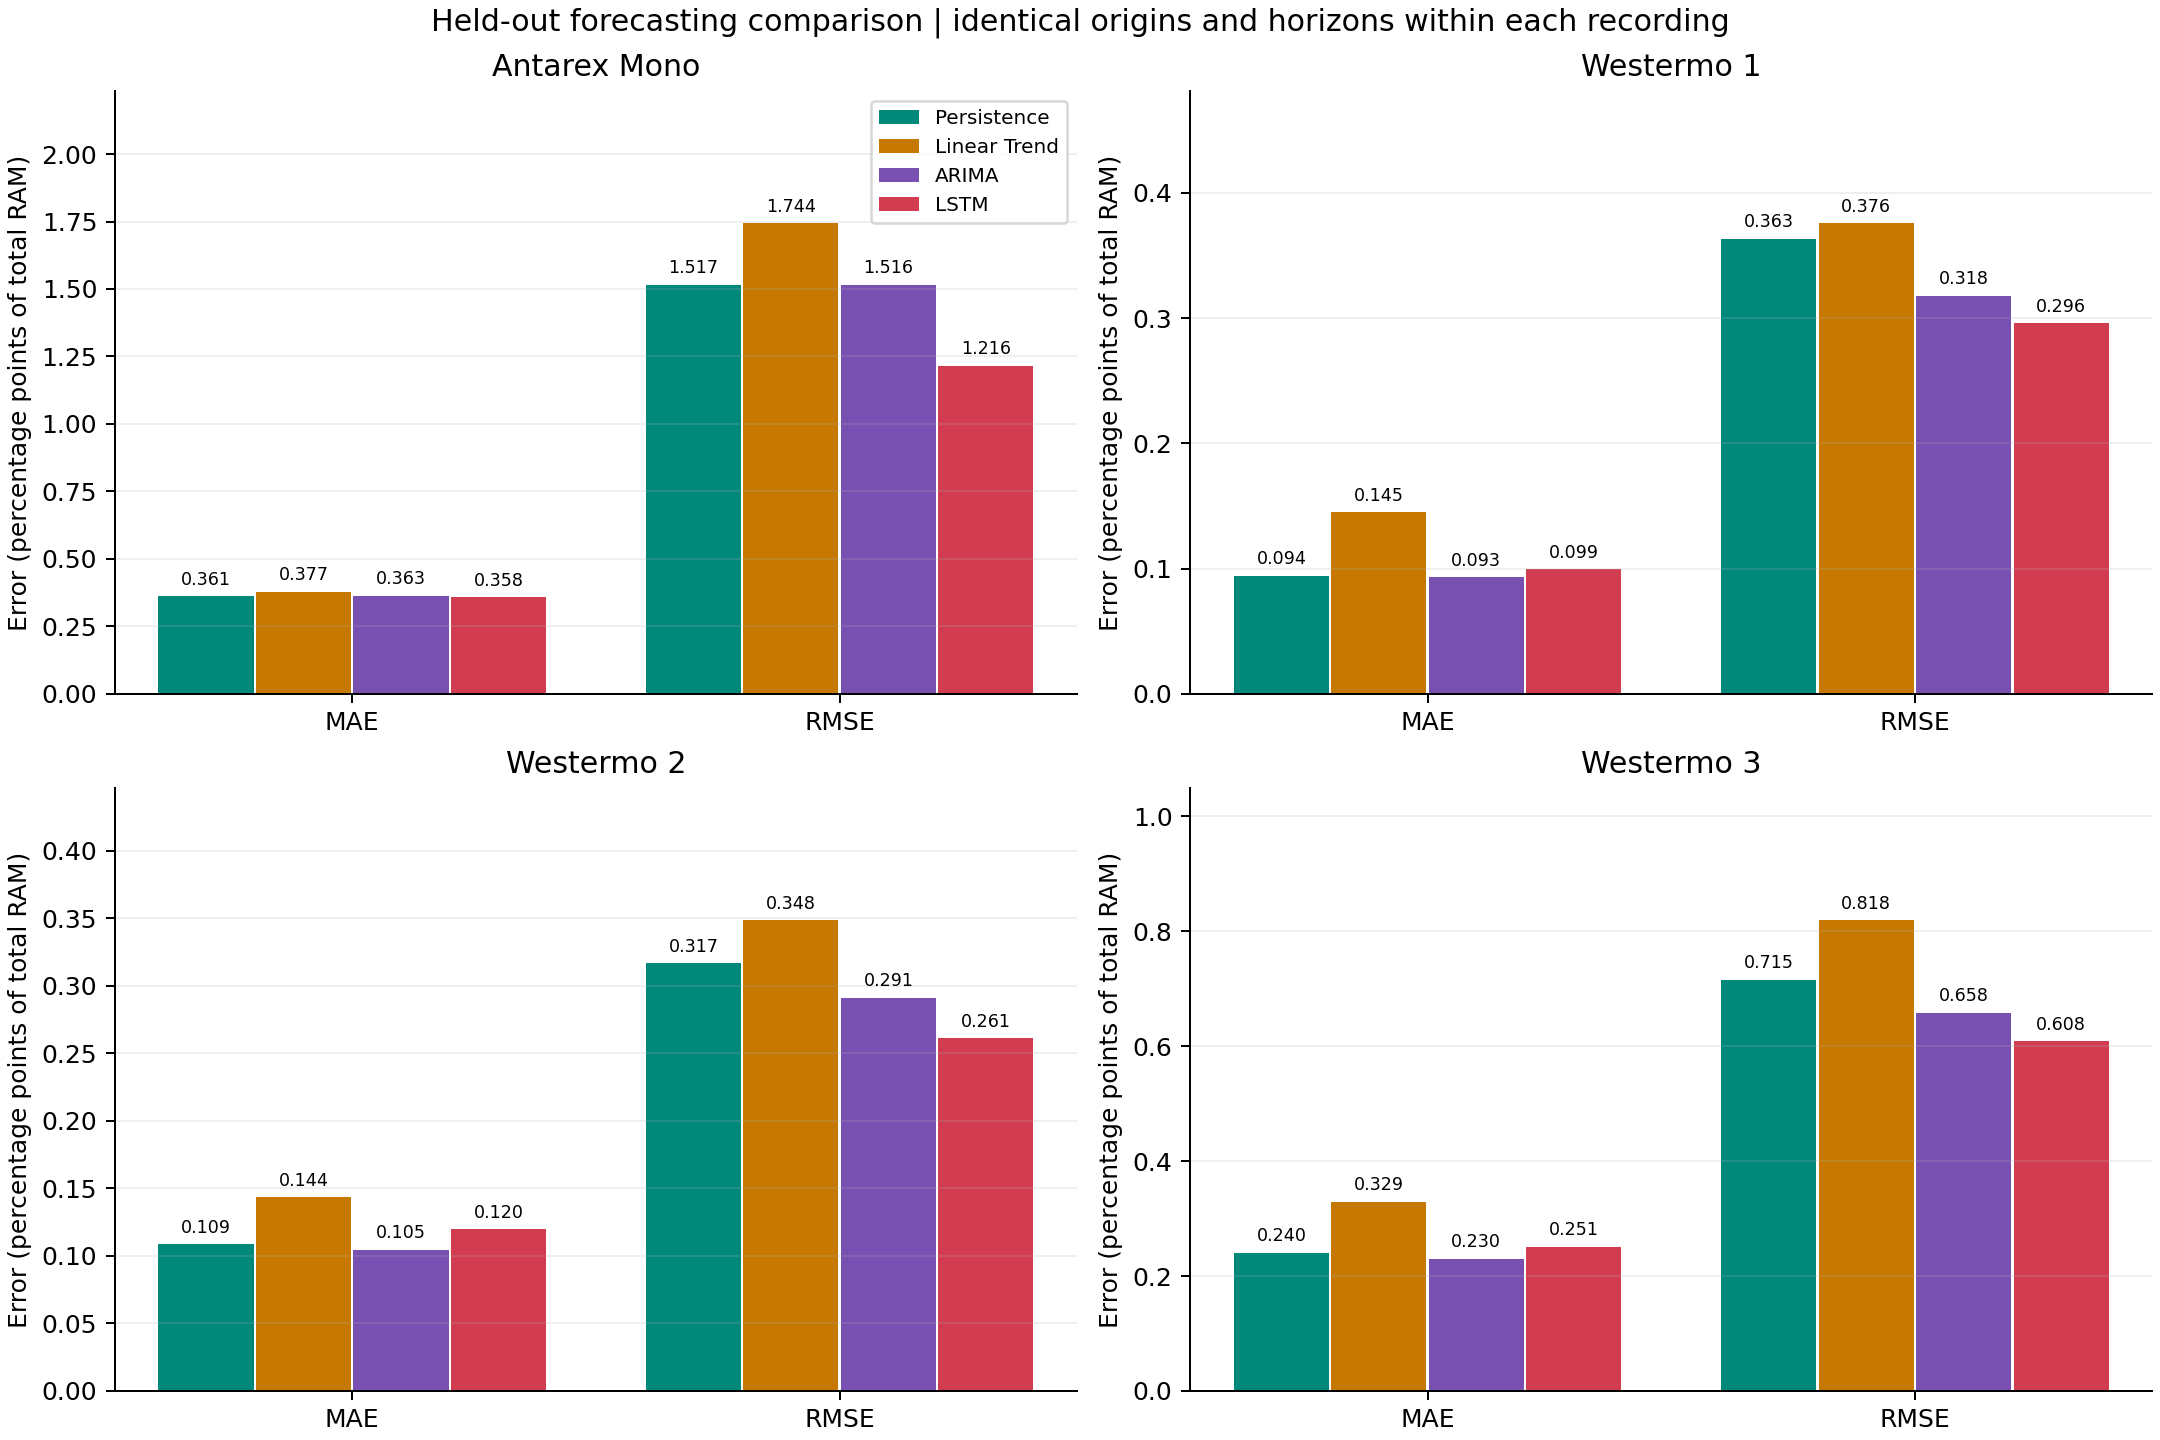

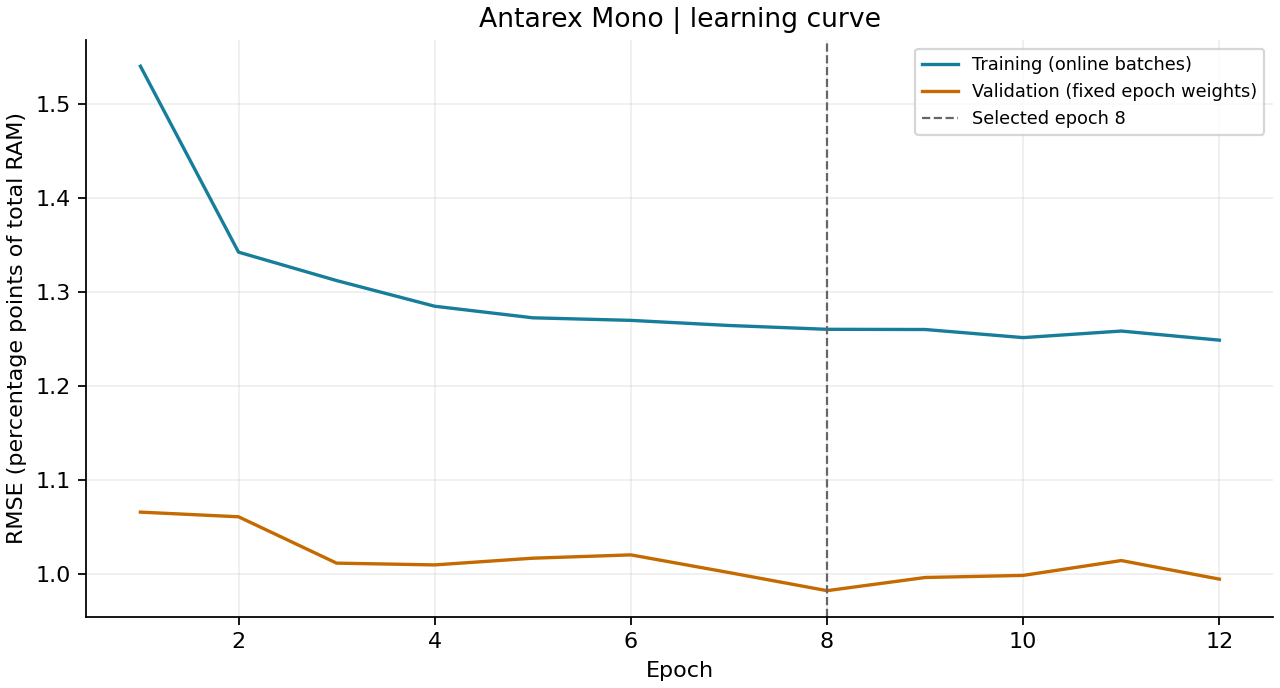

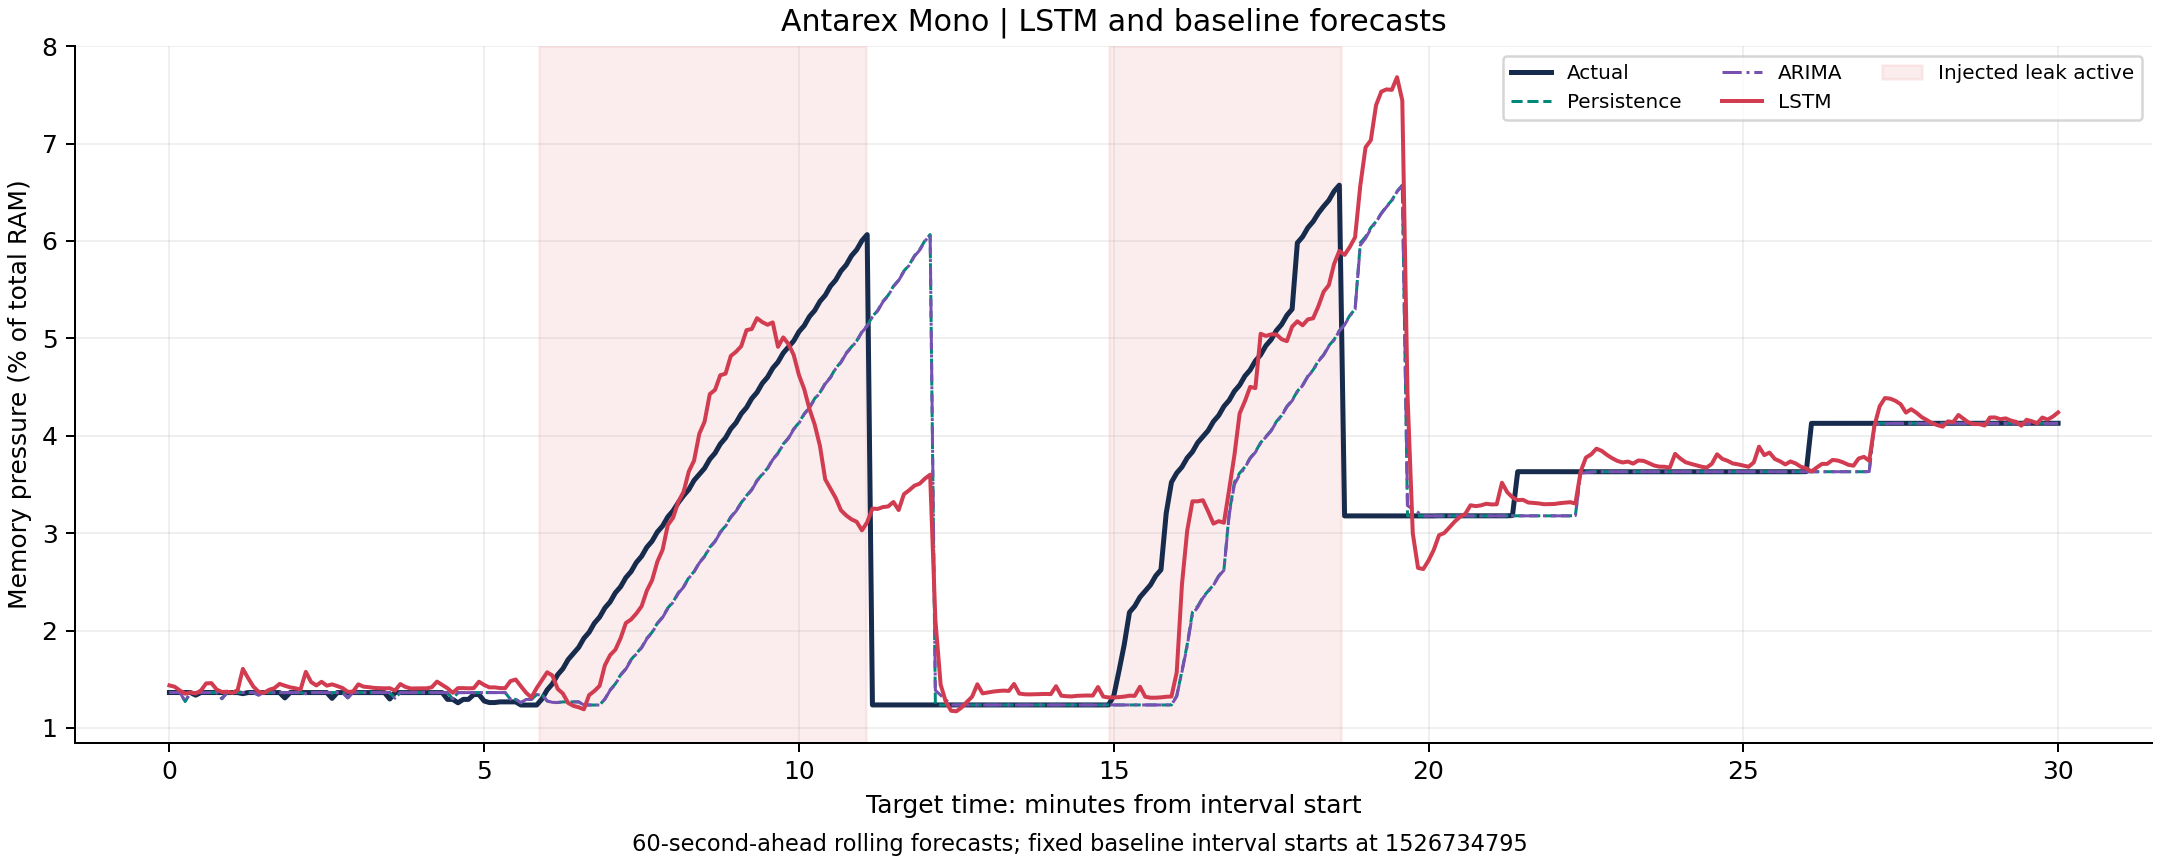

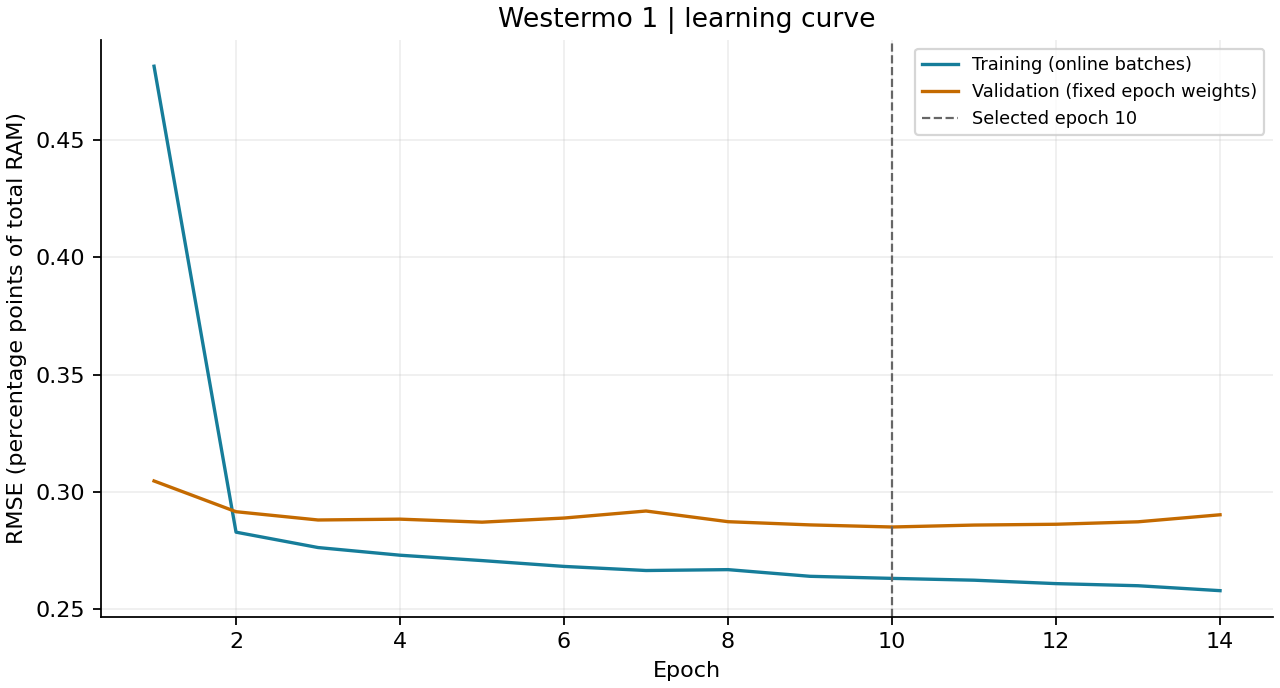

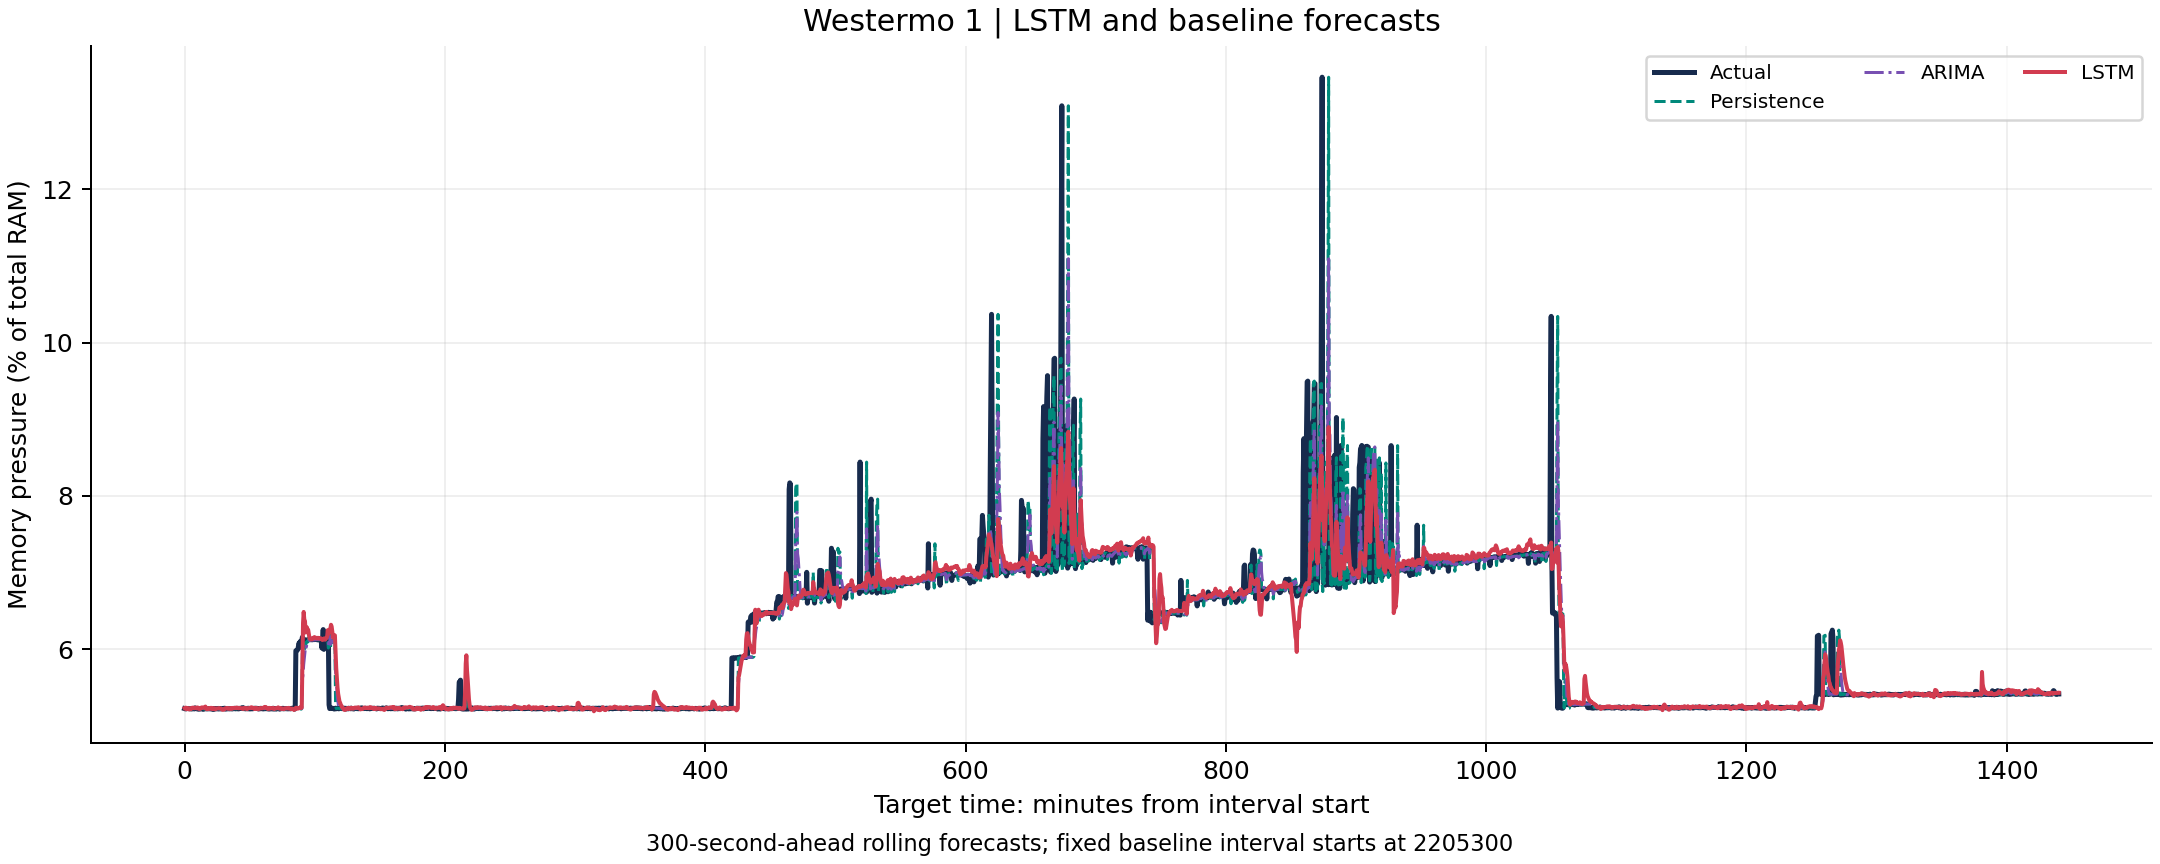

In [6]:
from PIL import Image
figures=['test_error_comparison.png','antarex_mono/learning_curve.png','antarex_mono/first_test_30min.png',
         'westermo_1/learning_curve.png','westermo_1/first_test_day.png']
for relative in figures:
    with Image.open(OUTPUT/relative) as picture:
        display(picture)


## 7. Reload saved weights, verify predictions and download the results
This recomputes the LSTM's forecasts from the saved checkpoints, checks the reported errors and confirms that selected model files are unchanged. The download contains model weights, resumable checkpoints, training history, parameters, forecasts, figures and a hash manifest.

In [7]:
checks=verify_results(SOURCE,OUTPUT,device_choice='auto')
print(checks)
receipt=package_results(OUTPUT,RESULT_PACKAGE)
print(receipt)
if IN_COLAB:
    from google.colab import files
    files.download(str(RESULT_PACKAGE))


{'all_checks_passed': True, 'saved_forecast_values_checked': 557056, 'lstm_forecasts_recomputed_from_saved_weights': True, 'selection_unchanged': True, 'maximum_checkpoint_reload_forecast_difference_fraction': 9.8879238130678e-17}
{'file': 'review2_lstm_results.zip', 'bytes': 8241969, 'sha256': 'd661eb4e9acf2ef931099ef9330fc3962e44226439fc654685d95fe7b6371bae', 'all_entry_hashes_verified': True}


## Checkpoint
The initial LSTM forecasting comparison is complete once the checks pass. Leak-warning precision/recall and detection delay, broader seed/ablation studies, and the research-paper draft remain separate later stages. The available data do not demonstrate warning lead time before memory exhaustion.
